<a href="https://colab.research.google.com/github/laboralit82-lab/ProcesamientoDelHabla/blob/main/TP3_chatbots_Mariela_Malizia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP3 Chatbots basados en recuperación de la información

En inglés information retrieval chatbots

# Motor de búsqueda

* Búsqueda por palabras clave: Extrae palabras clave de la pregunta del usuario y busca coincidencias en las preguntas almacenadas.

* Similitud del coseno: Si has representado las preguntas como vectores (por ejemplo, usando TF-IDF o word embeddings), puedes usar la similitud del coseno para medir la distancia entre las preguntas.

* Embeddings: Utiliza modelos de word embeddings como por ejemplo Word2Vec para obtener representaciones semánticas de las preguntas y las consultas del usuario.

## Librerías

Debes trabajar en Python. Puedes usar las librerías sklearn, pandas, spacy o nltk o gensim para el punto de usar o buscar embeddings.

In [1]:
!pip install spacy --quiet
!python -m spacy download es_core_news_sm --quiet
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 106.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Actividades



### 1) Elaborar un dataset de preguntas y respuestas para crear un Chatbot para un aplicación particular. ( 3 puntos )

1.1 Debe definir la aplicación (atención al cliente bancario, atención a estudiantes universitarios, etc).

1.2 El listado de preguntas y respuestas debe tener como mínimo 20 elementos pregunta - respuesta.

###  2) Crear el chatbot utilizando TFIDF y similitud del coseno. (1 punto)

### 3) Crear otro chatbot utilizando embeddings. Indique cuál embedding (1 punto) pre-entrenado de las librerías Spacy o nltk o gensim eligió. Justifique.

### 4) Muestra ambos chatbots funcionando (1 punto)

Adjuntar la lista de preguntas y respuestas utilizadas para probar el funcionamiento.

Releve o indique cuáles respondió correctamente y cuáles no.

### 5) Añade tus conclusiones de todo lo realizado (2 punto)

* Resalte e indique en cuáles respuestas falla o tiene problemas.
* Cuáles preguntas confunde.
* Compare los resultados de los chatbots.



### No olvides:

* Explicar tus decisiones y configuraciones. Añadir tus conclusiones.
* Anunciar en el foro cuál será tu aplicación y postear tu entrega y tus avances.
* Debes subir tu notebook a un repo GitHub público de tu propiedad compartido + enlace colab.
* Documentar todo el proceso.
* Citar tus fuentes





1. Definición de la aplicación

Aplicación elegida: Chatbot de orientación sobre evaluación psicológica laboral.

El objetivo de este proyecto es desarrollar un chatbot capaz de responder preguntas frecuentes relacionadas con la evaluación psicológica en el ámbito laboral.

La aplicación estará orientada a estudiantes de Psicología, profesionales de Recursos Humanos y personas interesadas en conocer los procesos de evaluación y selección de personal.

El chatbot proporcionará información sobre entrevistas laborales, evaluaciones psicotécnicas, competencias laborales, técnicas de evaluación y elaboración de perfiles profesionales.

Se desarrollarán dos versiones del chatbot: una basada en TF-IDF y similitud del coseno, y otra mediante embeddings preentrenados. El propósito será comparar su capacidad para identificar preguntas similares y recuperar respuestas adecuadas.

Justificación de la elección

Se seleccionó esta temática por su aplicación práctica en el ámbito de la Psicología Laboral y por la posibilidad de analizar cómo diferentes técnicas de procesamiento del lenguaje natural interpretan consultas formuladas de distintas maneras.

El chatbot tendrá una finalidad exclusivamente informativa y no realizará diagnósticos ni evaluaciones psicológicas individuales.

In [2]:
import pandas as pd

# Dataset de preguntas y respuestas sobre evaluación psicológica laboral

datos = {
    "pregunta": [
        "¿Qué es una evaluación psicológica laboral?",
        "¿Para qué sirve una evaluación psicotécnica?",
        "¿Qué es una entrevista por competencias?",
        "¿Qué son las competencias laborales?",
        "¿Qué es un perfil de puesto?",
        "¿Qué evalúa un test de personalidad?",
        "¿Qué es una prueba psicométrica?",
        "¿Qué es una técnica proyectiva?",
        "¿Qué es la selección de personal?",
        "¿Qué es el reclutamiento de personal?",
        "¿Qué es la inteligencia emocional?",
        "¿Qué es la tolerancia a la frustración?",
        "¿Qué significa trabajar en equipo?",
        "¿Qué es la capacidad de adaptación?",
        "¿Qué es la autonomía laboral?",
        "¿Qué es la capacidad de liderazgo?",
        "¿Qué es la orientación a resultados?",
        "¿Qué es la resolución de problemas?",
        "¿Qué es la comunicación asertiva?",
        "¿Qué es la capacidad de aprendizaje?",
        "¿Qué es la organización y planificación?",
        "¿Qué es la tolerancia a la presión?",
        "¿Qué es la motivación laboral?",
        "¿Qué es un informe psicotécnico?",
        "¿Qué es la confidencialidad en una evaluación laboral?"
    ],

    "respuesta": [
        "Es un proceso de evaluación que permite conocer características psicológicas relevantes para el desempeño de una persona en un puesto de trabajo.",
        "Sirve para explorar recursos personales, características de personalidad y competencias relacionadas con las exigencias de un puesto laboral.",
        "Es una entrevista que busca identificar comportamientos y experiencias anteriores relacionados con las competencias necesarias para un puesto.",
        "Son conocimientos, habilidades, actitudes y comportamientos que contribuyen al desempeño eficaz en una función laboral.",
        "Es una descripción de las funciones, responsabilidades, requisitos y competencias necesarias para desempeñar un puesto de trabajo.",
        "Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.",
        "Es un instrumento estandarizado que permite medir determinadas características psicológicas mediante procedimientos definidos.",
        "Es una técnica que utiliza estímulos con distintos grados de estructuración para explorar aspectos del funcionamiento psicológico.",
        "Es el proceso mediante el cual se identifican y evalúan candidatos para determinar su adecuación a un puesto de trabajo.",
        "Es el conjunto de acciones destinadas a atraer candidatos potencialmente adecuados para cubrir una posición laboral.",
        "Es la capacidad de reconocer, comprender y regular las propias emociones y relacionarse adecuadamente con las emociones de los demás.",
        "Es la capacidad de afrontar obstáculos, dificultades o resultados desfavorables sin perder el control emocional ni abandonar los objetivos.",
        "Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.",
        "Es la capacidad de ajustarse a cambios, nuevas situaciones y diferentes exigencias del entorno laboral.",
        "Es la capacidad de realizar tareas y tomar decisiones dentro del propio ámbito de responsabilidad sin requerir supervisión constante.",
        "Es la capacidad de orientar, motivar y coordinar a otras personas para alcanzar objetivos compartidos.",
        "Es la capacidad de dirigir los esfuerzos hacia el cumplimiento de metas y objetivos establecidos.",
        "Es la capacidad de analizar situaciones problemáticas, identificar alternativas y seleccionar soluciones adecuadas.",
        "Es la capacidad de expresar ideas, necesidades y opiniones de manera clara y respetuosa, considerando también a los demás.",
        "Es la capacidad de incorporar nuevos conocimientos y habilidades y aplicarlos en diferentes situaciones laborales.",
        "Es la capacidad de establecer prioridades, distribuir recursos y organizar actividades para alcanzar objetivos.",
        "Es la capacidad de mantener un desempeño adecuado frente a situaciones de exigencia, urgencia o elevada demanda laboral.",
        "Es el conjunto de factores internos y externos que impulsan, orientan y sostienen el comportamiento de una persona en el trabajo.",
        "Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.",
        "Es el principio ético que exige proteger la información obtenida durante una evaluación y comunicarla únicamente a las personas autorizadas, dentro de los límites legales y profesionales."
    ]
}

df = pd.DataFrame(datos)

print("Cantidad de preguntas y respuestas:", len(df))

display(df)

Cantidad de preguntas y respuestas: 25


,pregunta,respuesta
0,¿Qué es una evaluación psicológica laboral?,Es un proceso de evaluación que permite conoce...
1,¿Para qué sirve una evaluación psicotécnica?,"Sirve para explorar recursos personales, carac..."
2,¿Qué es una entrevista por competencias?,Es una entrevista que busca identificar compor...
3,¿Qué son las competencias laborales?,"Son conocimientos, habilidades, actitudes y co..."
4,¿Qué es un perfil de puesto?,"Es una descripción de las funciones, responsab..."
5,¿Qué evalúa un test de personalidad?,Explora características relativamente estables...
6,¿Qué es una prueba psicométrica?,Es un instrumento estandarizado que permite me...
7,¿Qué es una técnica proyectiva?,Es una técnica que utiliza estímulos con disti...
8,¿Qué es la selección de personal?,Es el proceso mediante el cual se identifican ...
9,¿Qué es el reclutamiento de personal?,Es el conjunto de acciones destinadas a atraer...


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Convertimos las preguntas en vectores TF-IDF
vectorizador = TfidfVectorizer()

matriz_tfidf = vectorizador.fit_transform(df["pregunta"])

# Función del chatbot
def chatbot_tfidf(consulta):
    consulta_vector = vectorizador.transform([consulta])

    similitudes = cosine_similarity(consulta_vector, matriz_tfidf)

    indice = similitudes.argmax()
    puntaje = similitudes[0][indice]

    if puntaje < 0.2:
        return "No tengo información suficiente para responder esa pregunta."

    return df["respuesta"].iloc[indice]

In [4]:
pregunta = "¿Para qué se utiliza un psicotécnico?"

respuesta = chatbot_tfidf(pregunta)

print("Pregunta:", pregunta)
print("Respuesta:", respuesta)

Pregunta: ¿Para qué se utiliza un psicotécnico?
Respuesta: Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.


In [5]:
pregunta = "¿Qué significa tener autonomía en el trabajo?"

respuesta = chatbot_tfidf(pregunta)

print("Pregunta:", pregunta)
print("Respuesta:", respuesta)

Pregunta: ¿Qué significa tener autonomía en el trabajo?
Respuesta: Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.


Primera prueba del chatbot TF-IDF

Se realizó una consulta sobre la utilidad de una evaluación psicotécnica. El chatbot recuperó incorrectamente la respuesta correspondiente a un informe psicotécnico. Este resultado evidencia una limitación del modelo TF-IDF para reconocer expresiones relacionadas semánticamente cuando presentan diferencias en su formulación.

In [6]:
# Preguntas para evaluar ambos chatbots

preguntas_prueba = [
    "¿Para qué se utiliza un psicotécnico?",
    "¿Qué significa tener autonomía en el trabajo?",
    "¿Cómo se evalúa la personalidad de un candidato?",
    "¿Qué diferencia hay entre reclutamiento y selección?",
    "¿Qué significa trabajar bajo presión?",
    "¿Para qué sirve una entrevista por competencias?",
    "¿Qué es un informe psicotécnico?",
    "¿Cómo se mide la inteligencia emocional?",
    "¿Qué significa adaptarse a los cambios laborales?",
    "¿Qué es la motivación laboral?"
]

# Ejecutamos las pruebas
for pregunta in preguntas_prueba:
    print("Pregunta:", pregunta)
    print("Respuesta:", chatbot_tfidf(pregunta))
    print("-" * 70)

Pregunta: ¿Para qué se utiliza un psicotécnico?
Respuesta: Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.
----------------------------------------------------------------------
Pregunta: ¿Qué significa tener autonomía en el trabajo?
Respuesta: Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.
----------------------------------------------------------------------
Pregunta: ¿Cómo se evalúa la personalidad de un candidato?
Respuesta: Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.
----------------------------------------------------------------------
Pregunta: ¿Qué diferencia hay entre reclutamiento y selección?
Respuesta: Es el proceso mediante el cual se identifican y evalúan candidatos para determinar su adecuación a un puesto de trabaj

In [7]:
# Guardamos las respuestas del primer chatbot

resultados_tfidf = []

for pregunta in preguntas_prueba:
    respuesta = chatbot_tfidf(pregunta)

    resultados_tfidf.append({
        "Pregunta": pregunta,
        "Respuesta TF-IDF": respuesta
    })

tabla_tfidf = pd.DataFrame(resultados_tfidf)

display(tabla_tfidf)

,Pregunta,Respuesta TF-IDF
0,¿Para qué se utiliza un psicotécnico?,Es un documento profesional que integra los re...
1,¿Qué significa tener autonomía en el trabajo?,Es la capacidad de colaborar con otras persona...
2,¿Cómo se evalúa la personalidad de un candidato?,Explora características relativamente estables...
3,¿Qué diferencia hay entre reclutamiento y sele...,Es el proceso mediante el cual se identifican ...
4,¿Qué significa trabajar bajo presión?,Es la capacidad de colaborar con otras persona...
5,¿Para qué sirve una entrevista por competencias?,Es una entrevista que busca identificar compor...
6,¿Qué es un informe psicotécnico?,Es un documento profesional que integra los re...
7,¿Cómo se mide la inteligencia emocional?,"Es la capacidad de reconocer, comprender y reg..."
8,¿Qué significa adaptarse a los cambios laborales?,"Son conocimientos, habilidades, actitudes y co..."
9,¿Qué es la motivación laboral?,Es el conjunto de factores internos y externos...


In [8]:
# Instalación de spaCy y del modelo en español
!pip install spacy --quiet
!python -m spacy download es_core_news_md --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 MB 20.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [9]:
import spacy
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# Cargamos el modelo preentrenado en español
nlp = spacy.load("es_core_news_md")

# Convertimos las preguntas del dataset en vectores
vectores_preguntas = np.array([
    nlp(pregunta).vector
    for pregunta in df["pregunta"]
])

# Creamos el chatbot con embeddings
def chatbot_embeddings(consulta):

    # Convertimos la consulta en un vector
    vector_consulta = nlp(consulta).vector.reshape(1, -1)

    # Calculamos la similitud del coseno
    similitudes = cosine_similarity(
        vector_consulta,
        vectores_preguntas
    )

    # Identificamos la pregunta más similar
    indice = similitudes.argmax()
    puntaje = similitudes[0][indice]

    # Establecemos un umbral mínimo de similitud
    if puntaje < 0.5:
        return "No tengo información suficiente para responder esa pregunta."

    return df["respuesta"].iloc[indice]

In [10]:
pregunta = "¿Para qué se utiliza un psicotécnico?"

respuesta = chatbot_embeddings(pregunta)

print("Pregunta:", pregunta)
print("Respuesta:", respuesta)

Pregunta: ¿Para qué se utiliza un psicotécnico?
Respuesta: Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.


In [11]:
# Guardamos las respuestas del chatbot con embeddings

resultados_embeddings = []

for pregunta in preguntas_prueba:
    respuesta = chatbot_embeddings(pregunta)

    resultados_embeddings.append({
        "Pregunta": pregunta,
        "Respuesta Embeddings": respuesta
    })

tabla_embeddings = pd.DataFrame(resultados_embeddings)

display(tabla_embeddings)

,Pregunta,Respuesta Embeddings
0,¿Para qué se utiliza un psicotécnico?,Explora características relativamente estables...
1,¿Qué significa tener autonomía en el trabajo?,Es la capacidad de colaborar con otras persona...
2,¿Cómo se evalúa la personalidad de un candidato?,Explora características relativamente estables...
3,¿Qué diferencia hay entre reclutamiento y sele...,Es la capacidad de colaborar con otras persona...
4,¿Qué significa trabajar bajo presión?,Es la capacidad de colaborar con otras persona...
5,¿Para qué sirve una entrevista por competencias?,"Sirve para explorar recursos personales, carac..."
6,¿Qué es un informe psicotécnico?,Es un documento profesional que integra los re...
7,¿Cómo se mide la inteligencia emocional?,Es la capacidad de mantener un desempeño adecu...
8,¿Qué significa adaptarse a los cambios laborales?,Es la capacidad de dirigir los esfuerzos hacia...
9,¿Qué es la motivación laboral?,Es el conjunto de factores internos y externos...


In [12]:
# Comparación de los resultados de ambos chatbots

comparacion = pd.merge(
    tabla_tfidf,
    tabla_embeddings,
    on="Pregunta"
)

# Mostrar todas las respuestas completas
pd.set_option("display.max_colwidth", None)

print("Comparación de los dos chatbots")
display(comparacion)

Comparación de los dos chatbots


,Pregunta,Respuesta TF-IDF,Respuesta Embeddings
0,¿Para qué se utiliza un psicotécnico?,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.
1,¿Qué significa tener autonomía en el trabajo?,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.","Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes."
2,¿Cómo se evalúa la personalidad de un candidato?,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.
3,¿Qué diferencia hay entre reclutamiento y selección?,Es el proceso mediante el cual se identifican y evalúan candidatos para determinar su adecuación a un puesto de trabajo.,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes."
4,¿Qué significa trabajar bajo presión?,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.","Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes."
5,¿Para qué sirve una entrevista por competencias?,Es una entrevista que busca identificar comportamientos y experiencias anteriores relacionados con las competencias necesarias para un puesto.,"Sirve para explorar recursos personales, características de personalidad y competencias relacionadas con las exigencias de un puesto laboral."
6,¿Qué es un informe psicotécnico?,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.
7,¿Cómo se mide la inteligencia emocional?,"Es la capacidad de reconocer, comprender y regular las propias emociones y relacionarse adecuadamente con las emociones de los demás.","Es la capacidad de mantener un desempeño adecuado frente a situaciones de exigencia, urgencia o elevada demanda laboral."
8,¿Qué significa adaptarse a los cambios laborales?,"Son conocimientos, habilidades, actitudes y comportamientos que contribuyen al desempeño eficaz en una función laboral.",Es la capacidad de dirigir los esfuerzos hacia el cumplimiento de metas y objetivos establecidos.
9,¿Qué es la motivación laboral?,"Es el conjunto de factores internos y externos que impulsan, orientan y sostienen el comportamiento de una persona en el trabajo.","Es el conjunto de factores internos y externos que impulsan, orientan y sostienen el comportamiento de una persona en el trabajo."


In [13]:
# Evaluación de las respuestas obtenidas

evaluacion_tfidf = [
    "Incorrecta",
    "Incorrecta",
    "Parcial",
    "Parcial",
    "Incorrecta",
    "Correcta",
    "Correcta",
    "Parcial",
    "Incorrecta",
    "Correcta"
]

evaluacion_embeddings = [
    "Parcial",
    "Incorrecta",
    "Parcial",
    "Incorrecta",
    "Incorrecta",
    "Incorrecta",
    "Correcta",
    "Incorrecta",
    "Incorrecta",
    "Correcta"
]

comparacion["Evaluación TF-IDF"] = evaluacion_tfidf
comparacion["Evaluación Embeddings"] = evaluacion_embeddings

display(comparacion)

,Pregunta,Respuesta TF-IDF,Respuesta Embeddings,Evaluación TF-IDF,Evaluación Embeddings
0,¿Para qué se utiliza un psicotécnico?,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.,Incorrecta,Parcial
1,¿Qué significa tener autonomía en el trabajo?,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.","Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.",Incorrecta,Incorrecta
2,¿Cómo se evalúa la personalidad de un candidato?,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.,Explora características relativamente estables de la personalidad que pueden influir en el comportamiento de una persona.,Parcial,Parcial
3,¿Qué diferencia hay entre reclutamiento y selección?,Es el proceso mediante el cual se identifican y evalúan candidatos para determinar su adecuación a un puesto de trabajo.,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.",Parcial,Incorrecta
4,¿Qué significa trabajar bajo presión?,"Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.","Es la capacidad de colaborar con otras personas, compartir responsabilidades y contribuir al logro de objetivos comunes.",Incorrecta,Incorrecta
5,¿Para qué sirve una entrevista por competencias?,Es una entrevista que busca identificar comportamientos y experiencias anteriores relacionados con las competencias necesarias para un puesto.,"Sirve para explorar recursos personales, características de personalidad y competencias relacionadas con las exigencias de un puesto laboral.",Correcta,Incorrecta
6,¿Qué es un informe psicotécnico?,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.,Es un documento profesional que integra los resultados de una evaluación psicológica laboral y presenta conclusiones relacionadas con el perfil del puesto.,Correcta,Correcta
7,¿Cómo se mide la inteligencia emocional?,"Es la capacidad de reconocer, comprender y regular las propias emociones y relacionarse adecuadamente con las emociones de los demás.","Es la capacidad de mantener un desempeño adecuado frente a situaciones de exigencia, urgencia o elevada demanda laboral.",Parcial,Incorrecta
8,¿Qué significa adaptarse a los cambios laborales?,"Son conocimientos, habilidades, actitudes y comportamientos que contribuyen al desempeño eficaz en una función laboral.",Es la capacidad de dirigir los esfuerzos hacia el cumplimiento de metas y objetivos establecidos.,Incorrecta,Incorrecta
9,¿Qué es la motivación laboral?,"Es el conjunto de factores internos y externos que impulsan, orientan y sostienen el comportamiento de una persona en el trabajo.","Es el conjunto de factores internos y externos que impulsan, orientan y sostienen el comportamiento de una persona en el trabajo.",Correcta,Correcta


Resultados de la evaluación:


,TF-IDF,Embeddings
Correcta,3,2
Parcial,3,2
Incorrecta,4,6


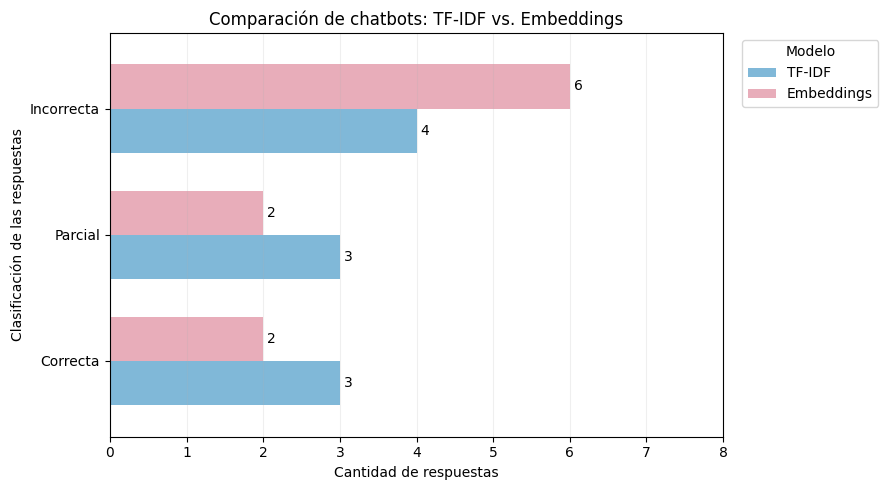

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

# Contamos las respuestas de cada categoría
categorias = ["Correcta", "Parcial", "Incorrecta"]

resultados = pd.DataFrame({
    "TF-IDF": [
        evaluacion_tfidf.count(categoria)
        for categoria in categorias
    ],
    "Embeddings": [
        evaluacion_embeddings.count(categoria)
        for categoria in categorias
    ]
}, index=categorias)

print("Resultados de la evaluación:")
display(resultados)

# Creamos el gráfico comparativo
ax = resultados.plot(
    kind="barh",
    figsize=(9, 5),
    color=["#80B8D8", "#E8ADBA"],
    width=0.7
)

plt.title("Comparación de chatbots: TF-IDF vs. Embeddings")
plt.xlabel("Cantidad de respuestas")
plt.ylabel("Clasificación de las respuestas")

# Colocamos la leyenda fuera del gráfico
plt.legend(
    title="Modelo",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xlim(0, 8)
plt.grid(axis="x", alpha=0.2)

# Mostramos los valores en cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3)

plt.tight_layout()
plt.show()

Análisis comparativo de los resultados

Se evaluaron ambos chatbots utilizando diez preguntas formuladas de manera idéntica para los dos modelos. Las respuestas se clasificaron como correctas, parcialmente correctas o incorrectas, considerando su adecuación al contenido de la consulta.

Los resultados preliminares muestran que el chatbot basado en TF-IDF obtuvo tres respuestas correctas, tres parcialmente correctas y cuatro incorrectas. Por su parte, el chatbot basado en embeddings obtuvo dos respuestas correctas, dos parcialmente correctas y seis incorrectas.

En esta evaluación, TF-IDF presentó un mejor desempeño. Sin embargo, ambos modelos evidenciaron dificultades para recuperar información cuando las preguntas fueron reformuladas o incluyeron conceptos relacionados.

Estos resultados permiten observar que la utilización de embeddings no garantiza necesariamente una mayor precisión y que el desempeño depende también de las características del dataset, la formulación de las preguntas y las configuraciones utilizadas.

Análisis de errores y limitaciones

Durante las pruebas se observaron dificultades en ambos modelos para identificar correctamente algunas consultas relacionadas con la evaluación psicológica laboral.

El chatbot basado en TF-IDF presentó errores principalmente cuando las preguntas fueron formuladas utilizando expresiones diferentes de las almacenadas en el dataset. Por ejemplo, confundió la utilidad de una evaluación psicotécnica con la definición de un informe psicotécnico. También presentó dificultades para reconocer conceptos como autonomía laboral, tolerancia a la presión y adaptación al cambio.

El chatbot basado en embeddings también mostró dificultades para distinguir determinadas competencias laborales. Por ejemplo, ante una consulta sobre autonomía, recuperó una respuesta relacionada con el trabajo en equipo. Asimismo, confundió la tolerancia a la presión con otras competencias y no logró responder adecuadamente algunas consultas sobre reclutamiento y selección.

Estas dificultades pueden relacionarse con el tamaño reducido del dataset, la similitud entre algunos conceptos y las limitaciones de las representaciones vectoriales utilizadas.

En particular, el modelo de spaCy empleado genera representaciones de las preguntas a partir de vectores de palabras, lo que no garantiza una interpretación precisa de su significado completo.

Los resultados muestran la importancia de ampliar el conjunto de preguntas, incorporar diferentes formas de expresar una misma consulta y ajustar los criterios de similitud para mejorar la recuperación de información.

5. Conclusiones generales

El desarrollo de este trabajo permitió explorar dos enfoques de recuperación de información aplicados a un chatbot de orientación sobre evaluación psicológica laboral: TF-IDF con similitud del coseno y embeddings preentrenados mediante spaCy.

A partir de un dataset de 25 preguntas y respuestas, se construyeron ambos modelos y se evaluó su funcionamiento mediante diez consultas, incluyendo preguntas directas y otras formuladas de manera diferente a las originales.

Los resultados evidenciaron que ninguno de los modelos logró responder correctamente todas las consultas. TF-IDF obtuvo un mejor desempeño en esta prueba, con tres respuestas correctas, mientras que el modelo basado en embeddings obtuvo dos. Sin embargo, estos resultados deben interpretarse considerando el tamaño reducido del dataset y la cantidad limitada de pruebas realizadas.

Se observaron dificultades especialmente en la diferenciación de conceptos relacionados, como autonomía, trabajo en equipo, tolerancia a la presión y evaluación psicotécnica. Esto demuestra que identificar similitudes entre palabras o representaciones vectoriales no implica necesariamente comprender el significado específico de una consulta.

Desde la perspectiva de la Psicología Laboral, considero especialmente importante que un sistema de recuperación de información pueda diferenciar conceptos que, aunque relacionados, representan competencias o procedimientos distintos. Una respuesta imprecisa puede generar interpretaciones equivocadas sobre el alcance de una evaluación psicológica o las características de una competencia laboral.

Como posibles mejoras, sería conveniente ampliar el dataset, incorporar preguntas alternativas para cada concepto, revisar los umbrales de similitud y realizar nuevas pruebas con diferentes formulaciones.

En conclusión, ambos enfoques constituyen herramientas útiles para desarrollar sistemas de orientación informativa. No obstante, sus resultados requieren supervisión y validación, especialmente cuando se aplican a ámbitos profesionales en los que la precisión conceptual resulta fundamental.

6. Justificación de las decisiones técnicas

Elección de TF-IDF y similitud del coseno

Se seleccionó TF-IDF como primer método porque permite representar numéricamente las preguntas considerando la importancia de las palabras dentro del conjunto de textos.

La similitud del coseno se utilizó para comparar la consulta del usuario con las preguntas almacenadas e identificar aquella que presenta mayor semejanza.

Se estableció inicialmente un umbral de similitud de 0.2 para evitar recuperar respuestas cuando la coincidencia entre las preguntas fuera demasiado baja. Este valor se adoptó como criterio experimental y no fue optimizado mediante un procedimiento sistemático.

Elección del modelo de embeddings

Para el segundo chatbot se seleccionó el modelo preentrenado es_core_news_md de spaCy, debido a que permite trabajar con textos en español y dispone de vectores de palabras preentrenados.

A diferencia de TF-IDF, que se basa en la importancia de las palabras dentro del conjunto de documentos, los embeddings permiten representar relaciones semánticas entre términos.

Se utilizó la representación vectorial de cada pregunta y la similitud del coseno para identificar la consulta almacenada más cercana.

Se estableció un umbral inicial de 0.5, también de carácter experimental.

Criterios de evaluación

Ambos modelos fueron evaluados utilizando las mismas diez preguntas, con el propósito de comparar sus respuestas bajo condiciones equivalentes.

Se establecieron tres categorías de evaluación: correcta, parcialmente correcta e incorrecta.

La clasificación se realizó considerando la pertinencia conceptual de las respuestas y no únicamente los valores de similitud obtenidos.

Limitaciones

Los umbrales seleccionados no fueron ajustados mediante una validación sistemática. Además, el dataset contiene únicamente 25 preguntas y respuestas, por lo que los resultados no pueden generalizarse a otros conjuntos de datos.

7. Fuentes y herramientas utilizadas
Python: lenguaje de programación utilizado para desarrollar los chatbots.
Pandas: biblioteca utilizada para organizar el dataset y presentar los resultados.
Scikit-learn: biblioteca utilizada para implementar TF-IDF y calcular la similitud del coseno.
spaCy: biblioteca de procesamiento del lenguaje natural utilizada para obtener embeddings preentrenados en español.
NumPy: biblioteca utilizada para manipular los vectores numéricos.
Matplotlib: biblioteca utilizada para representar gráficamente los resultados.
Google Colab: entorno de desarrollo y ejecución del notebook.

Documentación oficial:

Scikit-learn: Documentación de TfidfVectorizer
Scikit-learn: Documentación de cosine_similarity
spaCy: Modelos disponibles para español
Pandas: Documentación oficial

Uso de inteligencia artificial

Para el desarrollo de este trabajo se utilizó ChatGPT como herramienta de asistencia en la elaboración del código, la organización del dataset, la explicación de los procedimientos y la interpretación de los resultados.

Las respuestas de los chatbots fueron obtenidas mediante la ejecución de los modelos implementados en Google Colab. Los resultados se analizaron considerando su pertinencia respecto de los conceptos de evaluación psicológica laboral.